Importing libraries:

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

Load Dataset:

In [2]:
dataset=pd.read_csv("Mall_Customers.csv")

Features Split:

In [3]:
X=dataset.iloc[:,[3,4]].values

Standard Scaler:

In [4]:
from sklearn.preprocessing import StandardScaler
sc=StandardScaler()
X_scaled=sc.fit_transform(X)

Find the Best Bandwidth using Silhouette Score:

In [5]:
from sklearn.cluster import MeanShift
from sklearn.metrics import silhouette_score

for bw in [0.3, 0.5, 0.7, 1.0]:

    model = MeanShift(bandwidth=bw)
    labels = model.fit_predict(X_scaled)

    n_clusters = len(set(labels))

    if n_clusters > 1:
        score = silhouette_score(X_scaled, labels)
        print("Bandwidth:", bw)
        print("Clusters:", n_clusters)
        print("Silhouette Score:", score)
        print("----------------------")

Bandwidth: 0.3
Clusters: 34
Silhouette Score: 0.40372121088607693
----------------------
Bandwidth: 0.5
Clusters: 16
Silhouette Score: 0.40925103972231597
----------------------
Bandwidth: 0.7
Clusters: 7
Silhouette Score: 0.535040584275411
----------------------
Bandwidth: 1.0
Clusters: 4
Silhouette Score: 0.49090686056015653
----------------------


Train a Model:

In [6]:
from sklearn.cluster import MeanShift
cluster=MeanShift(bandwidth=0.7)
labels=cluster.fit_predict(X_scaled)

Display the Cluster lables:

In [7]:
labels

array([4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3,
       4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3,
       4, 3, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 2, 1, 0, 1, 2, 1, 2, 1,
       2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 0, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1,
       2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1,
       2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 5, 2, 5, 2, 5, 6, 5, 6, 5, 6, 5,
       6, 5])

Create a DataFrame to Existing Dataset:

In [8]:
Clustered_dataset=pd.DataFrame(dataset)

Add Labels to the Existing Dataset:

In [9]:
Clustered_dataset["Clustered_Group"]=labels
Clustered_dataset

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100),Clustered_Group
0,1,Male,19,15,39,4
1,2,Male,21,15,81,3
2,3,Female,20,16,6,4
3,4,Female,23,16,77,3
4,5,Female,31,17,40,4
...,...,...,...,...,...,...
195,196,Female,35,120,79,5
196,197,Female,45,126,28,6
197,198,Male,32,126,74,5
198,199,Male,32,137,18,6


Plot the Cluster's Graph:

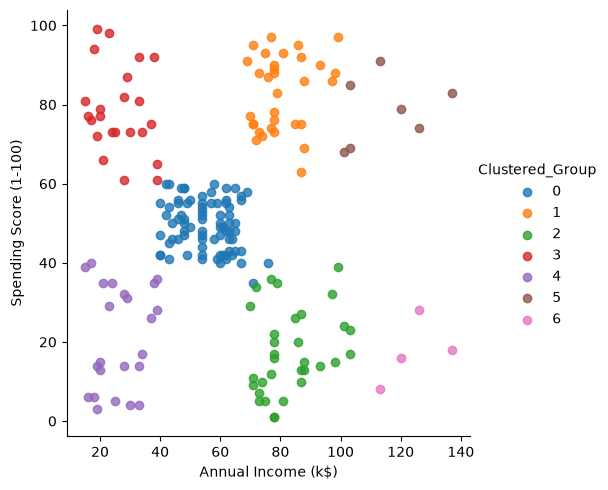

In [10]:
import seaborn as sns
facet=sns.lmplot(data=Clustered_dataset,x=Clustered_dataset.columns[3],y=Clustered_dataset.columns[4],hue=Clustered_dataset.columns[5],fit_reg=False,legend=True)
facet

Evaluation Metrics:

In [11]:
from sklearn.metrics import silhouette_score
score=silhouette_score(X_scaled,labels)
print("The Model Segregated score(-1 to +1) :",score)

The Model Segregated score(-1 to +1) : 0.535040584275411


Display the Required datas:

In [12]:
print("Number of Clusters:", len(set(labels)))

print("Number of Iterations:", cluster.n_iter_)

Number of Clusters: 7
Number of Iterations: 12


Average Annual Income and Spending Score by Cluster for Final Understanding:

In [13]:
cluster_profile=Clustered_dataset.groupby('Clustered_Group')[
    ['Annual Income (k$)','Spending Score (1-100)']
    ].mean()
print(cluster_profile)

                 Annual Income (k$)  Spending Score (1-100)
Clustered_Group                                            
0                         55.291139               49.569620
1                         80.375000               82.937500
2                         83.218750               17.593750
3                         26.304348               78.565217
4                         26.304348               20.913043
5                        114.714286               78.428571
6                        124.000000               17.500000


Count the Dataset Lables Based on Uniques:

In [14]:
print(Clustered_dataset['Clustered_Group'].value_counts())

Clustered_Group
0    79
1    32
2    32
4    23
3    23
5     7
6     4
Name: count, dtype: int64


Save the Scaling,Model & Cluster_Dataset:

In [15]:
import pickle
sc_filename='StandardScaler.sav'
model_filename='finalized_model.sav'
dataset_filename='Deployment_dataset.sav'
pickle.dump(sc,open(sc_filename,'wb'))
pickle.dump(cluster,open(model_filename,'wb'))
pickle.dump(cluster_profile,open(dataset_filename,'wb'))